# **04.2 - Convolutional Neural Network: Small VGG-Style CNN**

This a small-scale, VGG-style network that retains ReLU, Max Pooling, and 3x3 kernels Its purpose is to learn and predict CIFAR-10 dataset. CIFAR-10 was created by Alex Krizhevsky, Vinod Nair, and Geoffrey Hinton.

**Dataset citation:** Krizhevsky, A. (2009). Learning multiple layers of features from tiny images (Chapter 3). University of Toronto.


## **Libraries**

In [15]:
import random
import numpy
import torch
from torch import nn
from torchvision import datasets, transforms
from torch.optim import SGD
from torch.utils.data import DataLoader
from torch.utils.data import random_split
from torchvision.transforms import ToTensor
from matplotlib import pyplot as plt
import copy

## **Hyperparameters**

In [16]:
batch_size = 64
learning_rate = 0.01
nums_epoch = 80 # Epoch is one complete pass through the training set
prev_acc = 0

## **Data Loading, Split, Tensor Conversion**

In [18]:
# Training / Validation / Test Split
transform = transforms.ToTensor()

train_full = datasets.CIFAR10(
    root="./cifar10",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root="./cifar10",
    train=False,
    download=True,
    transform=transform
)

train_size = int(0.8*len(train_full))
val_size = len(train_full) - train_size

generator = torch.Generator().manual_seed(42) #Reproducible Split for hyperparameter testing

train_dataset, val_dataset = random_split(
    train_full,
    [train_size,val_size],
    generator=generator
)

# Data Loaders
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

## **Model**

### **Model Architecture**

In [19]:
# Convolutional Neural Network Architecture
class SmallVGG(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 32, 3, stride=1)
        self.relu1 = nn.ReLU()
        self.conv2 = nn.Conv2d(32, 32, 3, stride=1)
        self.relu2 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        self.conv3 = nn.Conv2d(32, 64, 3, stride=1)
        self.relu3 = nn.ReLU()
        self.conv4 = nn.Conv2d(64, 64, 3, stride=1)
        self.relu4 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        self.fc1 = nn.Linear(1600, 128)
        self.relu5 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(128, 10)

    def forward(self, x):
        y = self.conv1(x)
        y = self.relu1(y)
        y = self.conv2(y)
        y = self.relu2(y)
        y = self.pool1(y)

        y = self.conv3(y)
        y = self.relu3(y)
        y = self.conv4(y)
        y = self.relu4(y)
        y = self.pool2(y)

        y = y.view(y.shape[0], -1)  # Flattening

        y = self.fc1(y)
        y = self.relu5(y)
        y = self.dropout(y)
        y = self.fc2(y)

        return y

# Instance, Loss Function, Optimizer
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(device)
model = SmallVGG().to(device)
loss_function = nn.CrossEntropyLoss()
optimizer = SGD(model.parameters(), lr=learning_rate)

cuda


### **Model Training and Validation**

epoch =  0  training loss =  2.302022727203369  validation loss =  2.3020815363355505  difference =  5.880913218136996e-05
epoch =  10  training loss =  1.633618145942688  validation loss =  1.6417959632387586  difference =  0.0081778172960707
epoch =  20  training loss =  1.331383295249939  validation loss =  1.3667931351692053  difference =  0.035409839919266384
epoch =  30  training loss =  1.0707838906288147  validation loss =  1.1497717719928475  difference =  0.07898788136403279
epoch =  40  training loss =  0.8848590737342834  validation loss =  1.0299978039826556  difference =  0.1451387302483722
epoch =  50  training loss =  0.6994807836532593  validation loss =  0.9321545810456489  difference =  0.23267379739238958
epoch =  60  training loss =  0.5242436154842377  validation loss =  0.8922441970011231  difference =  0.3680005815168854
epoch =  70  training loss =  0.42430224549770357  validation loss =  0.9277521333876689  difference =  0.5034498878899654


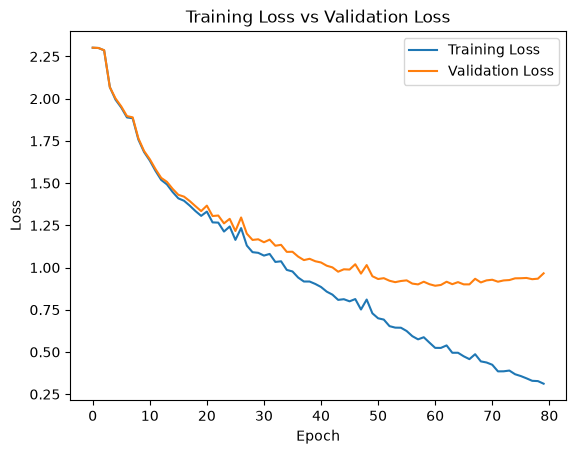

Training Accuracy: 0.828
Validation Accuracy: 0.695
Best epoch: 60, Best validation loss: 0.8922441970011231


In [20]:
loss_list = []
val_loss_list = []
training_accuracy_list = []
val_accuracy_list = []

best_val_loss = float('inf')
best_weights = None
best_epoch = None

for epoch in range(nums_epoch):

    # --------------------
    # Training Run
    # --------------------

    model.train()

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        prediction = model(x_batch)
        loss = loss_function(prediction, y_batch)

        # Gradient Descent
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # --------------------
    # Training / Validation Evaluation
    # --------------------

    model.eval()

    with torch.no_grad():

        # Training loss and accuracy for completed epoch
        train_loss = 0
        training_correct = 0
        training_total = 0

        for x_batch, y_batch in train_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            train_prediction = model(x_batch)
            batch_loss = loss_function(train_prediction, y_batch)

            train_loss += batch_loss.item()

            train_class = torch.argmax(train_prediction, dim=1)
            training_correct += (train_class == y_batch).sum().item()
            training_total += len(y_batch)

        train_loss = train_loss / len(train_loader)
        training_accuracy = training_correct / training_total

        loss_list.append(train_loss)
        training_accuracy_list.append(training_accuracy)


        # Validation loss and accuracy for completed epoch
        val_loss = 0
        val_correct = 0
        val_total = 0

        for x_batch, y_batch in val_loader:

            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)

            val_prediction = model(x_batch)
            batch_loss = loss_function(val_prediction, y_batch)

            val_loss += batch_loss.item()

            val_class = torch.argmax(val_prediction, dim=1)
            val_correct += (val_class == y_batch).sum().item()
            val_total += len(y_batch)

        val_loss = val_loss / len(val_loader)
        val_accuracy = val_correct / val_total

        val_loss_list.append(val_loss)
        val_accuracy_list.append(val_accuracy)


        # Best Weights Tracking
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_weights = copy.deepcopy(model.state_dict())
            best_epoch = epoch


        # Print Epoch Performance
        if epoch % 10 == 0:
            print(
                'epoch = ', epoch,
                ' training loss = ', train_loss,
                ' validation loss = ', val_loss,
                ' difference = ',
                abs(train_loss - val_loss)
            )


# Training Loss vs Validation Loss Plot
plt.plot(loss_list, label='Training Loss')
plt.plot(val_loss_list, label='Validation Loss')

plt.title('Training Loss vs Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


# -------------------------------------------
# Final Training / Validation Evaluation
# Using best validation weights
# -------------------------------------------

assert best_weights is not None
model.load_state_dict(best_weights)
model.eval()

with torch.no_grad():

    # Training evaluation using best weights
    train_correct = 0
    train_total = 0

    for x_batch, y_batch in train_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        train_prediction = model(x_batch)

        train_class = torch.argmax(train_prediction, dim=1)
        train_correct += (train_class == y_batch).sum().item()
        train_total += len(y_batch)

    training_accuracy = train_correct / train_total


    # Validation evaluation using best weights
    val_correct = 0
    val_total = 0

    for x_batch, y_batch in val_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        val_prediction = model(x_batch)

        val_class = torch.argmax(val_prediction, dim=1)
        val_correct += (val_class == y_batch).sum().item()
        val_total += len(y_batch)

    val_accuracy = val_correct / val_total


# Report Out

print(f"Training Accuracy: {round(training_accuracy, 3)}")
print(f"Validation Accuracy: {round(val_accuracy, 3)}")

print(
    f"Best epoch: {best_epoch}, "
    f"Best validation loss: {best_val_loss}"
)

### **Model Testing and Results**

In [22]:
# Best baseline weights. Remove if new training best-weights are to be used
# best_weights = torch.load(
#    "smallVGG_baseline_best_weights.pth",
#    map_location=device
#)

assert best_weights is not None
model.load_state_dict(best_weights)
model.eval()

with torch.no_grad():

    test_loss = 0
    test_correct = 0
    test_total = 0

    for x_batch, y_batch in test_loader:

        x_batch = x_batch.to(device)
        y_batch = y_batch.to(device)

        test_prediction = model(x_batch)
        batch_loss = loss_function(test_prediction, y_batch)

        test_loss += batch_loss.item()

        test_class = torch.argmax(test_prediction, dim=1)
        test_correct += (test_class == y_batch).sum().item()
        test_total += len(y_batch)

    test_loss = test_loss / len(test_loader)
    test_accuracy = test_correct / test_total

print(f"Test Loss: {round(test_loss, 4)}")
print(f"Test Accuracy: {round(test_accuracy, 3)}")

Test Loss: 0.9019
Test Accuracy: 0.692


## **Single Image Prediction**

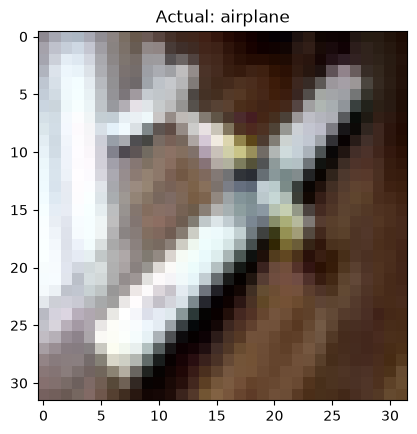

-----------------------------------------------------
Predicted Class: bird


In [34]:
# Actual Image
i = random.randrange(len(test_dataset))
image, label = test_dataset[i]

plt.imshow(image.permute(1, 2, 0))
plt.title(f"Actual: {test_dataset.classes[label]}")
plt.show()

print('-----------------------------------------------------')

# Model Prediction
single_image = image.unsqueeze(0)

model.eval()

with torch.no_grad():
    output = model(single_image.to(device))

prediction = torch.argmax(output, dim=1).item()

#print(f"Actual Class: {test_dataset.classes[label]}")
print(f"Predicted Class: {test_dataset.classes[prediction]}")

## **Results**

Four training runs were completed using the small VGG-style CNN on CIFAR-10.

| Run | Conv Channels | Classifier | Dropout | Best Epoch | Best Val Loss | Train Acc | Val Acc |
|---|---|---|---|---:|---:|---:|---:|
| 1 | 32 -> 64 | 1600 -> 128 -> 32 -> 10 | No | 32 | 1.1807 | 70.9% | 58.9% |
| 2 | 32 -> 64 | 1600 -> 128 -> 10 | No | 28 | 1.1157 | 75.2% | 62.7% |
| 3 | 16 -> 32 | 800 -> 128 -> 10 | No | 32 | 1.1147 | 72.9% | 61.9% |
| 4 | 32 -> 64 | 1600 -> 128 -> 10 | 0.5 | 60 | 0.8922 | 82.8% | 69.5% |

Run 1 showed substantial overfitting. Training loss continued toward zero while validation loss began increasing after approximately 30 epochs.

Run 2 removed the additional 32-neuron fully connected layer. Validation accuracy improved from 58.9% to 62.7%, suggesting that the original classifier contained unnecessary capacity.

Run 3 reduced the convolutional channels from 32/64 to 16/32. This reduced model capacity but did not improve generalization, producing slightly lower validation accuracy than Run 2.

Run 4 returned to the Run 2 architecture and added dropout with p = 0.5 after the hidden fully connected layer. This produced the strongest result, increasing validation accuracy to 69.5% and reducing validation loss to 0.8922.

The best validation weights from Run 4 were evaluated on the untouched test set:

- Test Loss: 0.9019
- Test Accuracy: 69.2%

The close agreement between validation accuracy (69.5%) and test accuracy (69.2%) suggests that the improvement observed with dropout generalized to unseen data.

Overall:
- Simplifying the fully connected classifier improved generalization.
- Reducing convolutional width provided little benefit.
- Dropout produced the largest improvement by reducing overfitting.